In [57]:
#all  important libraries for EDA report
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import datetime as datetime
import warnings
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8")
sns.set_palette("husl")
print("all libraries imported successfully")

all libraries imported successfully


In [58]:
# load data set
df = pd.read_csv("retail_sales.csv")
df.head(10)

,Date,Category,Sales,Quantity,Profit,Region
0,1/1/2023,Electronics,1149.014246,11.0,383.664245,North
1,1/1/2023,Clothing,958.520710,7.0,224.054049,East
2,1/1/2023,Home Goods,1473.763845,2.0,466.593090,South
3,1/1/2023,Sports,1230.230419,6.0,123.310460,West
4,1/1/2023,NaN?,828.585950,12.0,88.591355,East
5,1/2/2023,Electronics,722.775149,10.0,82.396149,West
6,1/2/2023,Clothing,788.996859,15.0,225.271072,West
7,1/2/2023,Home Goods,358.113803,3.0,128.198339,East
8,1/2/2023,Sports,819.923845,2.0,250.298077,East
9,1/2/2023,Books,1284.231946,7.0,363.436353,West


In [59]:
# Basic data information and Structure
print("Dataset Basic informtion")
print(f"Data Demension {df.shape[0]} Rows * {df.shape[1]} Columns")
print("Columns name and Data_Types")
print(df.dtypes)

Dataset Basic informtion
Data Demension 1825 Rows * 6 Columns
Columns name and Data_Types
Date            str
Category        str
Sales       float64
Quantity    float64
Profit      float64
Region          str
dtype: object


In [60]:
print("printing missing values ")
print(df.isnull().sum())
print("Dataset summary")
df.info()

printing missing values 
Date        0
Category    4
Sales       2
Quantity    5
Profit      0
Region      5
dtype: int64
Dataset summary
<class 'pandas.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      1825 non-null   str    
 1   Category  1821 non-null   str    
 2   Sales     1823 non-null   float64
 3   Quantity  1820 non-null   float64
 4   Profit    1825 non-null   float64
 5   Region    1820 non-null   str    
dtypes: float64(3), str(3)
memory usage: 85.7 KB


In [61]:
# How we fill missing values if found
mean_sales = df['Sales'].mean()
df['Sales'] = df['Sales'].fillna(mean_sales)

mean_quantity = df['Quantity'].mean()
df['Quantity'] = df['Quantity'].fillna(mean_quantity)

mode_region = df['Region'].mode()[0]
df['Region'] = df['Region'].fillna(mode_region)

mode_category = df['Category'].mode()[0]
df['Category'] = df['Category'].fillna(mode_category)


In [62]:
print("printing missing values ")
print(df.isnull().sum())

printing missing values 
Date        0
Category    0
Sales       0
Quantity    0
Profit      0
Region      0
dtype: int64


In [63]:
print("DATA CLEANINIG AND TYPE CONVERSION")
df["Date"]=pd.to_datetime(df["Date"])
df["MonthName"]=df["Date"].dt.month_name()
df["quarter"]=df["Date"].dt.quarter
df["Month"]=df["Date"].dt.month
df["DayOfWeek"]=df["Date"].dt.day_name()
#Ensure that numeric column are perfectely numeric
numeric_columns=['Sales','Quantity','Profit']
for col in numeric_columns:
    df[col]=pd.to_numeric(df[col],errors="coerce")
print("Data types after conversion")
print(df.dtypes)
print(f"Date range ={df["Date"].min() } to {df["Date"].max()}")

DATA CLEANINIG AND TYPE CONVERSION
Data types after conversion
Date         datetime64[us]
Category                str
Sales               float64
Quantity            float64
Profit              float64
Region                  str
MonthName               str
quarter               int32
Month                 int32
DayOfWeek               str
dtype: object
Date range =2023-01-01 00:00:00 to 2023-12-31 00:00:00


In [64]:
#Basic Stataical Summary
print("Descriptive statistics for numerical columns")
print(df[["Sales","Quantity","Profit"]].describe())


Descriptive statistics for numerical columns
             Sales     Quantity       Profit
count  1825.000000  1825.000000  1825.000000
mean    980.482677    10.053846   248.696130
std     336.571942     5.507806   118.159627
min       0.000000     0.000000     0.000000
25%     784.267165     5.000000   156.916498
50%     996.596443    10.000000   229.344557
75%    1208.163533    15.000000   324.867847
max    1888.932537    19.000000   703.228418


In [75]:
print("\nCategory-wise Summary:")
category_summary = df.groupby('Category').agg({
    'Sales': ['count', 'sum', 'mean', 'std'],
    'Profit': ['sum', 'mean'],
    'Quantity': ['sum', 'mean']
}).round(2) # round function use for round off after . to 2 number
print(category_summary)


Category-wise Summary:
            Sales                                Profit         Quantity  \
            count        sum     mean     std       sum    mean      sum   
Category                                                                   
Books         364  370971.87  1019.15  336.39  92304.45  253.58  3737.00   
Clothing      369  355420.13   963.20  336.42  90889.44  246.31  3670.00   
Electronics   360  363354.18  1009.32  342.23  89894.08  249.71  3587.00   
Home Goods    364  347493.83   954.65  332.39  87447.82  240.24  3777.00   
Sports        364  347665.55   955.13  330.74  92065.22  252.93  3542.27   

                    
              mean  
Category            
Books        10.27  
Clothing      9.95  
Electronics   9.96  
Home Goods   10.38  
Sports        9.73  


In [66]:
# For removing Unwanted text categories
df = df[~df['Category'].isin(['NaN', 'NaN?', 'Null',"Nan"])]

# Step 2: Category-wise Summary Report generate karne ke liye
print("\nCategory-wise Summary:")
category_summary = df.groupby('Category').agg({
    'Sales': ['count', 'sum', 'mean', 'std'],
    'Profit': ['sum', 'mean'],
    'Quantity': ['sum', 'mean']
}).round(2)
print(category_summary)


Category-wise Summary:
            Sales                                Profit         Quantity  \
            count        sum     mean     std       sum    mean      sum   
Category                                                                   
Books         364  370971.87  1019.15  336.39  92304.45  253.58  3737.00   
Clothing      369  355420.13   963.20  336.42  90889.44  246.31  3670.00   
Electronics   361  365070.89  1011.28  343.78  90439.70  250.53  3595.00   
Home Goods    364  347493.83   954.65  332.39  87447.82  240.24  3777.00   
Sports        364  347665.55   955.13  330.74  92065.22  252.93  3542.27   

                    
              mean  
Category            
Books        10.27  
Clothing      9.95  
Electronics   9.96  
Home Goods   10.38  
Sports        9.73  


In [67]:
print("n Region wise Summary")
# Region mein mojood text wale NaN ya Null ko remove karne ke liye
df = df[~df['Region'].isin(['NaN', 'Null', 'Nan'])]

Region_summary=df.groupby("Region").agg({
    'Profit':["sum","mean"],
    'Sales': ["sum","mean"]
}).round(2)
print(Region_summary)

n Region wise Summary
           Profit              Sales        
              sum    mean        sum    mean
Region                                      
East     98885.03  249.08  393593.51  991.42
North   112126.47  243.75  449275.52  976.69
South   119453.52  244.78  472629.00  968.50
West    122135.99  256.59  469407.52  986.15


In [74]:
#Monthly Sales trend Analysis
Monthly_sales = df.groupby(["Month","MonthName"]).agg({
    "Sales": "sum",
    "Profit" :'sum',
    "Quantity":'sum'
}).reset_index().round(2)
Monthly_sales=Monthly_sales.sort_values("Month")
print("Monthly Sales Summary")
print(Monthly_sales)

Monthly Sales Summary
    Month  MonthName      Sales    Profit  Quantity
0       1    January  144554.25  38442.01   1501.27
1       2   February  132215.41  34353.12   1517.00
2       3      March  145321.20  38584.60   1447.00
3       4      April  138160.99  37895.20   1446.00
4       5        May  150774.98  40527.69   1603.00
5       6       June  152605.75  39042.69   1570.00
6       7       July  162111.12  40208.96   1536.00
7       8     August  148020.45  34675.63   1489.00
8       9  September  153094.70  37796.76   1598.00
9      10    October  151272.28  36019.38   1569.00
10     11   November  146795.61  36344.05   1461.00
11     12   December  159978.81  38710.92   1576.00


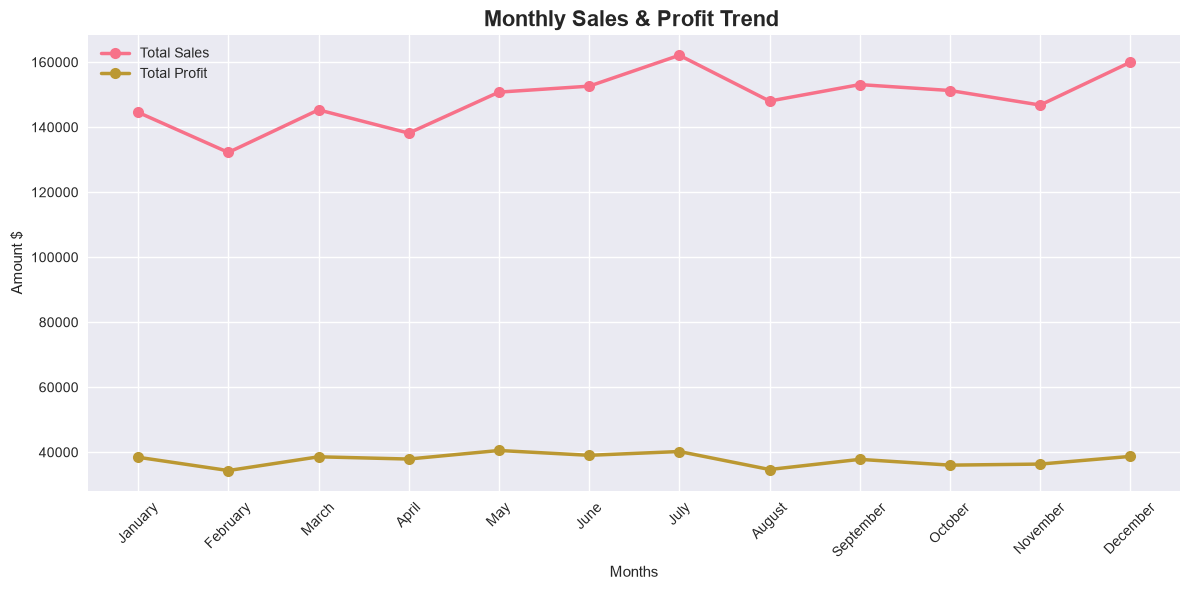

In [77]:
# Visualization :Monthly Trend
plt.figure(figsize=(12,6))
plt.plot(Monthly_sales["MonthName"],Monthly_sales["Sales"],
         marker="o",linewidth=2.5,markersize=8, label="Total Sales")
plt.plot(Monthly_sales["MonthName"],Monthly_sales["Profit"],
         marker="o",linewidth=2.5,markersize=8, label="Total Profit")
plt.title("Monthly Sales & Profit Trend ",fontsize=16,fontweight='bold')
plt.xlabel("Months")
plt.ylabel("Amount $")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [78]:
# Category Performance Analysis (Sorted by Sales)
print("=== CATEGORY PERFORMANCE ANALYSIS ===")

category_performance = df.groupby('Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).sort_values('Sales', ascending=False)

print("\nCategory Performance (Sorted by Sales):")
print(category_performance)

=== CATEGORY PERFORMANCE ANALYSIS ===

Category Performance (Sorted by Sales):
                     Sales        Profit     Quantity
Category                                             
Books        370971.872558  92304.452141  3737.000000
Electronics  363354.178178  89894.080069  3587.000000
Clothing     355420.126737  90889.437106  3670.000000
Sports       347665.545975  92065.220851  3542.269231
Home Goods   347493.827088  87447.820056  3777.000000


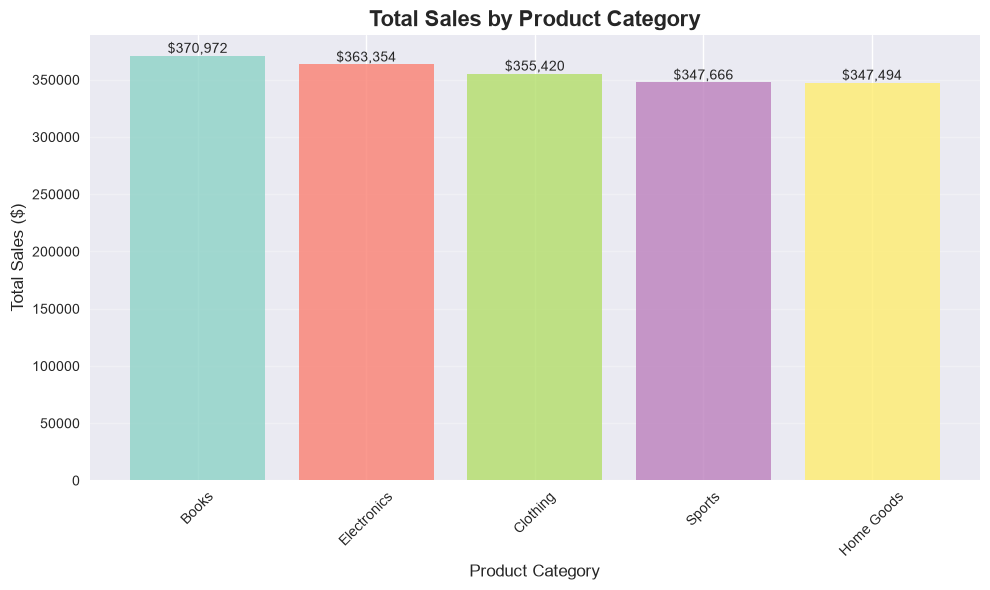

In [83]:
# Visualization 2: Top Categories by Sales
plt.figure(figsize=(10, 6))
colors = plt.cm.Set3(np.linspace(0, 1, len(category_performance)))
bars = plt.bar(category_performance.index, category_performance['Sales'], 
               color=colors, alpha=0.8)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'${height:,.0f}', ha='center', va='bottom')

plt.title('Total Sales by Product Category', fontsize=16, fontweight='bold')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [86]:
#Regional_performance analysis
Regional_performance=df.groupby("Region").agg({
    'Profit':["sum","mean","count"],
    'Sales': ["sum","mean"]
}).round(2)
print("Regional_performance analysis")
print(Regional_performance)

Regional_performance analysis
           Profit                    Sales        
              sum    mean count        sum    mean
Region                                            
East     98885.03  249.08   397  393593.51  991.42
North   112126.47  243.75   460  449275.52  976.69
South   119453.52  244.78   488  472629.00  968.50
West    122135.99  256.59   476  469407.52  986.15


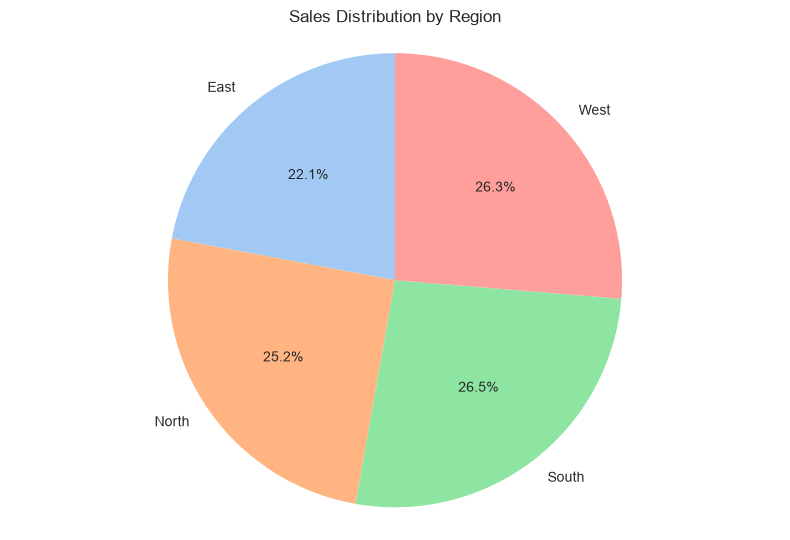

In [90]:
plt.Figure(figsize=(10,6))
regional_data=df.groupby("Region")["Sales"].sum()
plt.pie(regional_data,labels=regional_data.index,autopct="%1.1f%%",
        startangle=90,colors=sns.color_palette("pastel"))
plt.title("Sales Distribution by Region")
plt.tight_layout()
plt.axis("equal")
plt.show()

=== DAY OF WEEK ANALYSIS ===

Average Performance by Day of Week:
             Sales  Profit  Quantity
DayOfWeek                           
Monday      981.29  252.83     10.24
Tuesday     979.07  243.02     10.32
Wednesday   965.23  237.57     10.18
Thursday    966.83  237.62      9.78
Friday     1014.31  259.80     10.00
Saturday    972.78  253.31      9.66
Sunday      981.69  255.57     10.21


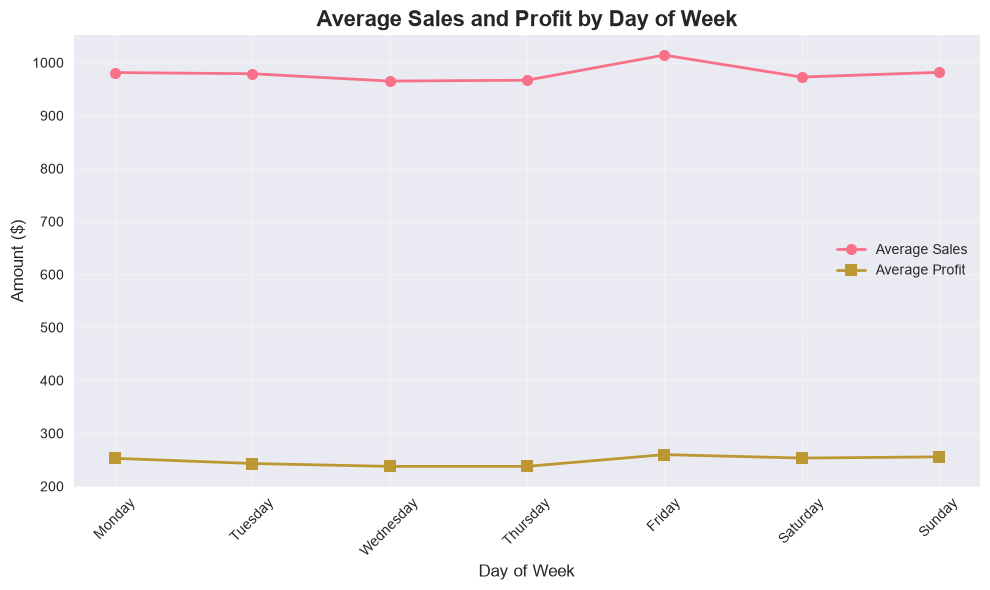

In [91]:
# Day of Week Analysis
print("=== DAY OF WEEK ANALYSIS ===")

# Define proper order for days (using pd.Categorical for custom sorting)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['DayOfWeek'] = pd.Categorical(df['DayOfWeek'], categories=day_order, ordered=True)

# Group by Day of Week and calculate mean for Sales, Profit, and Quantity
daily_performance = df.groupby('DayOfWeek').agg({
    'Sales': 'mean',
    'Profit': 'mean',
    'Quantity': 'mean'
}).round(2)

print("\nAverage Performance by Day of Week:")
print(daily_performance)


# Visualization 4: Daily Sales Pattern (Line Chart)
plt.figure(figsize=(10, 6))

plt.plot(daily_performance.index, daily_performance['Sales'],
         marker='o', linewidth=2, markersize=8, label='Average Sales')

plt.plot(daily_performance.index, daily_performance['Profit'],
         marker='s', linewidth=2, markersize=8, label='Average Profit')

plt.title('Average Sales and Profit by Day of Week', fontsize=16, fontweight='bold')
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Amount ($)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Correlation analysis 
Correlation Matrix
             Sales    Profit  Quantity     Month
Sales     1.000000  0.522573  0.056901  0.066934
Profit    0.522573  1.000000  0.028578 -0.032809
Quantity  0.056901  0.028578  1.000000  0.002290
Month     0.066934 -0.032809  0.002290  1.000000


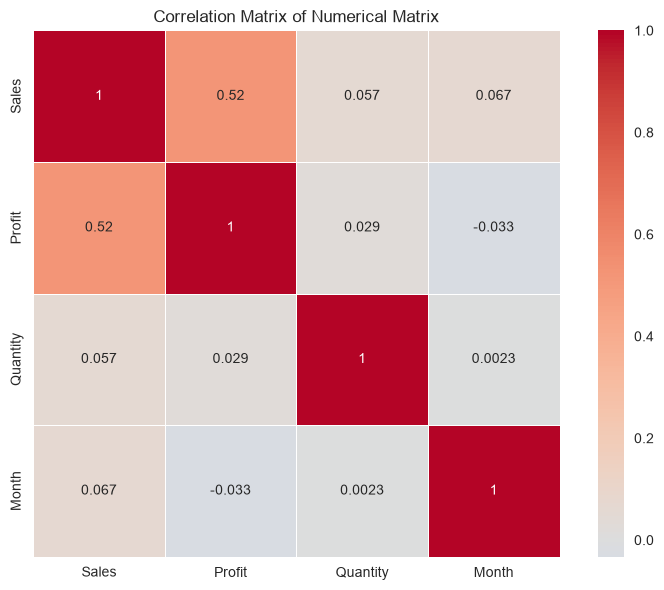

In [ ]:
#numerical column for correlations
print("Correlation analysis ")
Numerical_df=df[["Sales","Profit","Quantity","Month"]]
correlation_matrix=Numerical_df.corr()
print("Correlation Matrix")
print(correlation_matrix)
# visual correlation
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",center=0,square=True,linewidths=0.5)
plt.title("Correlation Matrix of Numerical Matrix")
plt.tight_layout()
plt.show()

Mini dashboard for Retail_sales


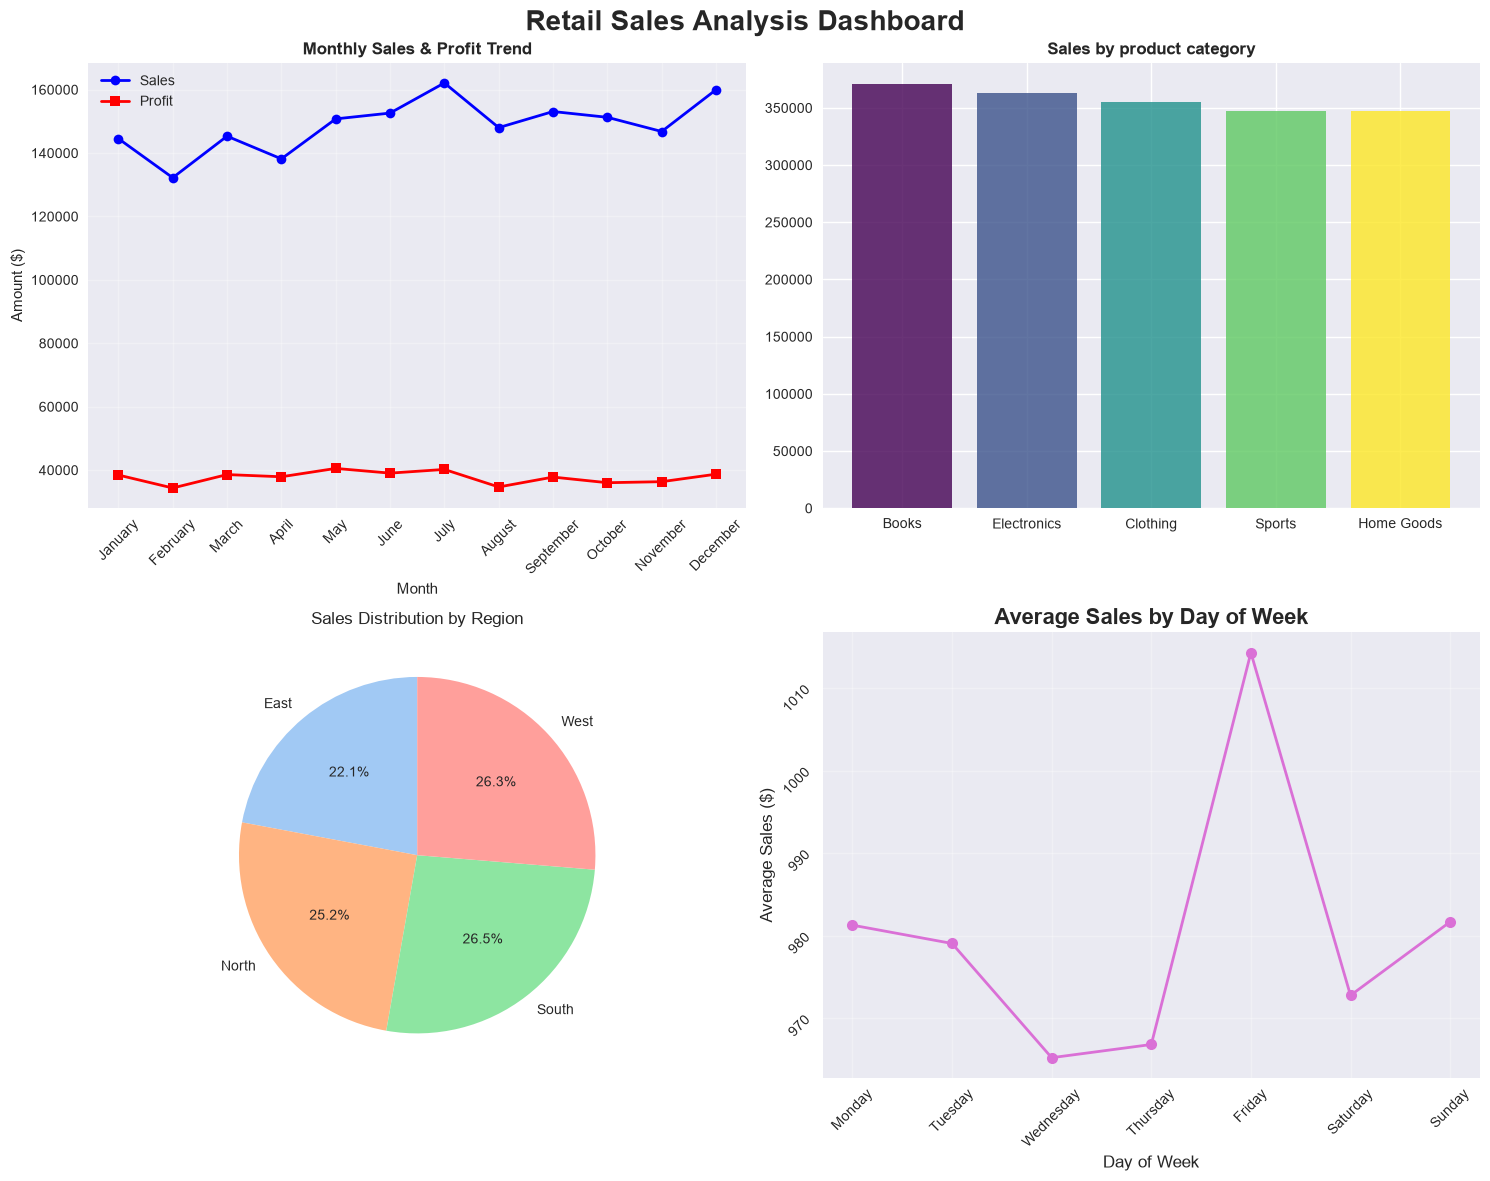

In [109]:
print("Mini dashboard for Retail_sales")
fig,axes=plt.subplots(2,2,figsize=(15,12))
fig.suptitle('Retail Sales Analysis Dashboard', fontsize=20, fontweight='bold')

# Chart 1: Monthly Sales Trend (Top-Left)
axes[0,0].plot(Monthly_sales['MonthName'], Monthly_sales['Sales'], 
               marker='o', linewidth=2, color='blue', label='Sales')
axes[0,0].plot(Monthly_sales['MonthName'], Monthly_sales['Profit'], 
               marker='s', linewidth=2, color='red', label='Profit')
axes[0,0].set_title('Monthly Sales & Profit Trend', fontweight='bold')
axes[0,0].set_xlabel('Month')
axes[0,0].set_ylabel('Amount ($)')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)
axes[0,0].tick_params(axis='x', rotation=45)

# Chart 2: Top Categories (Top-right)
colors = plt.cm.viridis(np.linspace(0, 1, len(category_performance)))
bars = axes[0,1].bar(category_performance.index, category_performance['Sales'], 
                     color=colors, alpha=0.8)
axes[0,1].set_title('Sales by product category', fontweight='bold')
# chart 3 : region wise
regional_data=df.groupby("Region")["Sales"].sum()

axes[1,0].pie(regional_data,labels=regional_data.index,autopct="%1.1f%%",
        startangle=90,colors=sns.color_palette("pastel"))
axes[1,0].set_title("Sales Distribution by Region")

# chart 4
axes[1,1].plot(daily_performance.index, daily_performance['Sales'], 
         marker='o', linewidth=2, markersize=8, color='orchid')

axes[1,1].set_title('Average Sales by Day of Week', fontsize=16, fontweight='bold')
axes[1,1].set_xlabel('Day of Week', fontsize=12)
axes[1,1].set_ylabel('Average Sales ($)', fontsize=12)
axes[1,1].grid(True, alpha=0.3)
axes[1,1].tick_params(rotation=45)
plt.tight_layout()
plt.show()


In [110]:
# Key Insights and Business Recommendations
print("=== KEY INSIGHTS AND RECOMMENDATIONS ===")

print("\n📊 KEY FINDINGS:")
print("1. Top Performing Category:", category_performance.index[0])
print("2. Best Performing Region:", regional_data.idxmax())
print("3. Highest Sales Month:", Monthly_sales.loc[Monthly_sales['Sales'].idxmax(), 'MonthName'])
print("4. Best Day of Week:", daily_performance['Sales'].idxmax())
print("5. Total Annual Sales: ${:,.2f}".format(df['Sales'].sum()))
print("6. Total Annual Profit: ${:,.2f}".format(df['Profit'].sum()))

print("\n💡 BUSINESS RECOMMENDATIONS:")
print("1. Focus marketing efforts on", category_performance.index[0], "category")
print("2. Investigate performance in lower-performing regions")
print("3. Plan promotions around", daily_performance['Sales'].idxmax(), "to maximize sales")
print("4. Allocate inventory based on monthly trend patterns")
print("5. Monitor correlation between quantity and profit for pricing strategy")

print("\n📈 PROFITABILITY ANALYSIS:")
profit_margin = (df['Profit'].sum() / df['Sales'].sum()) * 100
print(f"Overall Profit Margin: {profit_margin:.2f}%")

# Category profit margins
category_margins = (category_performance['Profit'] / category_performance['Sales']) * 100
print("\nProfit Margins by Category:")
for category, margin in category_margins.items():
    print(f"  {category}: {margin:.2f}%")

=== KEY INSIGHTS AND RECOMMENDATIONS ===

📊 KEY FINDINGS:
1. Top Performing Category: Books
2. Best Performing Region: South
3. Highest Sales Month: July
4. Best Day of Week: Friday
5. Total Annual Sales: $1,784,905.55
6. Total Annual Profit: $452,601.01

💡 BUSINESS RECOMMENDATIONS:
1. Focus marketing efforts on Books category
2. Investigate performance in lower-performing regions
3. Plan promotions around Friday to maximize sales
4. Allocate inventory based on monthly trend patterns
5. Monitor correlation between quantity and profit for pricing strategy

📈 PROFITABILITY ANALYSIS:
Overall Profit Margin: 25.36%

Profit Margins by Category:
  Books: 24.88%
  Electronics: 24.74%
  Clothing: 25.57%
  Sports: 26.48%
  Home Goods: 25.17%
